Walkthrough Video - https://drive.google.com/file/d/12uvD6BoC1Xt5a_h4Emo8BgbU5Hlqi4on/view?usp=sharing

**Visualize and Analyze the Data**

In [72]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # running locally: data is read from ./data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [73]:
import numpy as np

In [74]:
import pandas as pd

In [75]:
df = pd.read_csv('data/Customer-Data - 2.csv')

In [76]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [78]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204822,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634780,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [79]:
features_na = [features for features in df.columns if df[features].isnull().sum() > 0]
for feature in features_na:
    print(feature, np.round(df[feature].isnull().mean(), 4),  ' % missing values')
else:
    print("No missing value found")

CREDIT_LIMIT 0.0001  % missing values
MINIMUM_PAYMENTS 0.035  % missing values
No missing value found


In [80]:
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].dropna()
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].dropna()

# Removing all the missing values from dataset

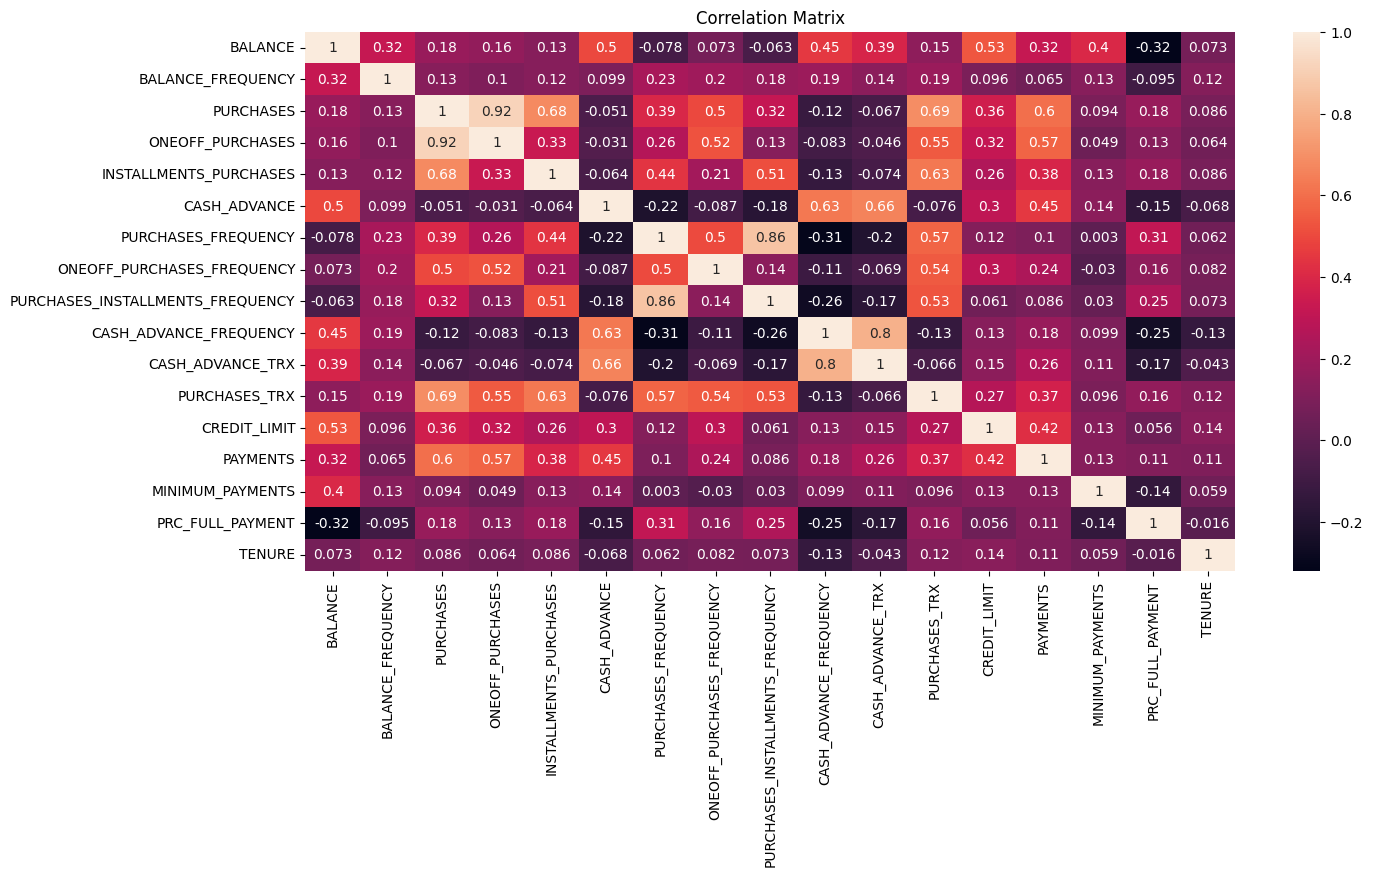

In [81]:
# Making a correlation matrix to find highly correlated variables

import matplotlib.pyplot as plt
import seaborn as sns

cor_mat = df.select_dtypes(include=[np.number]).corr()

fig = plt.figure(figsize=(15, 7))
sns.heatmap(cor_mat, annot=True)

plt.title("Correlation Matrix")
plt.show()

**Question 1a - Reducing skewness of data using log, power and exponential transformation**

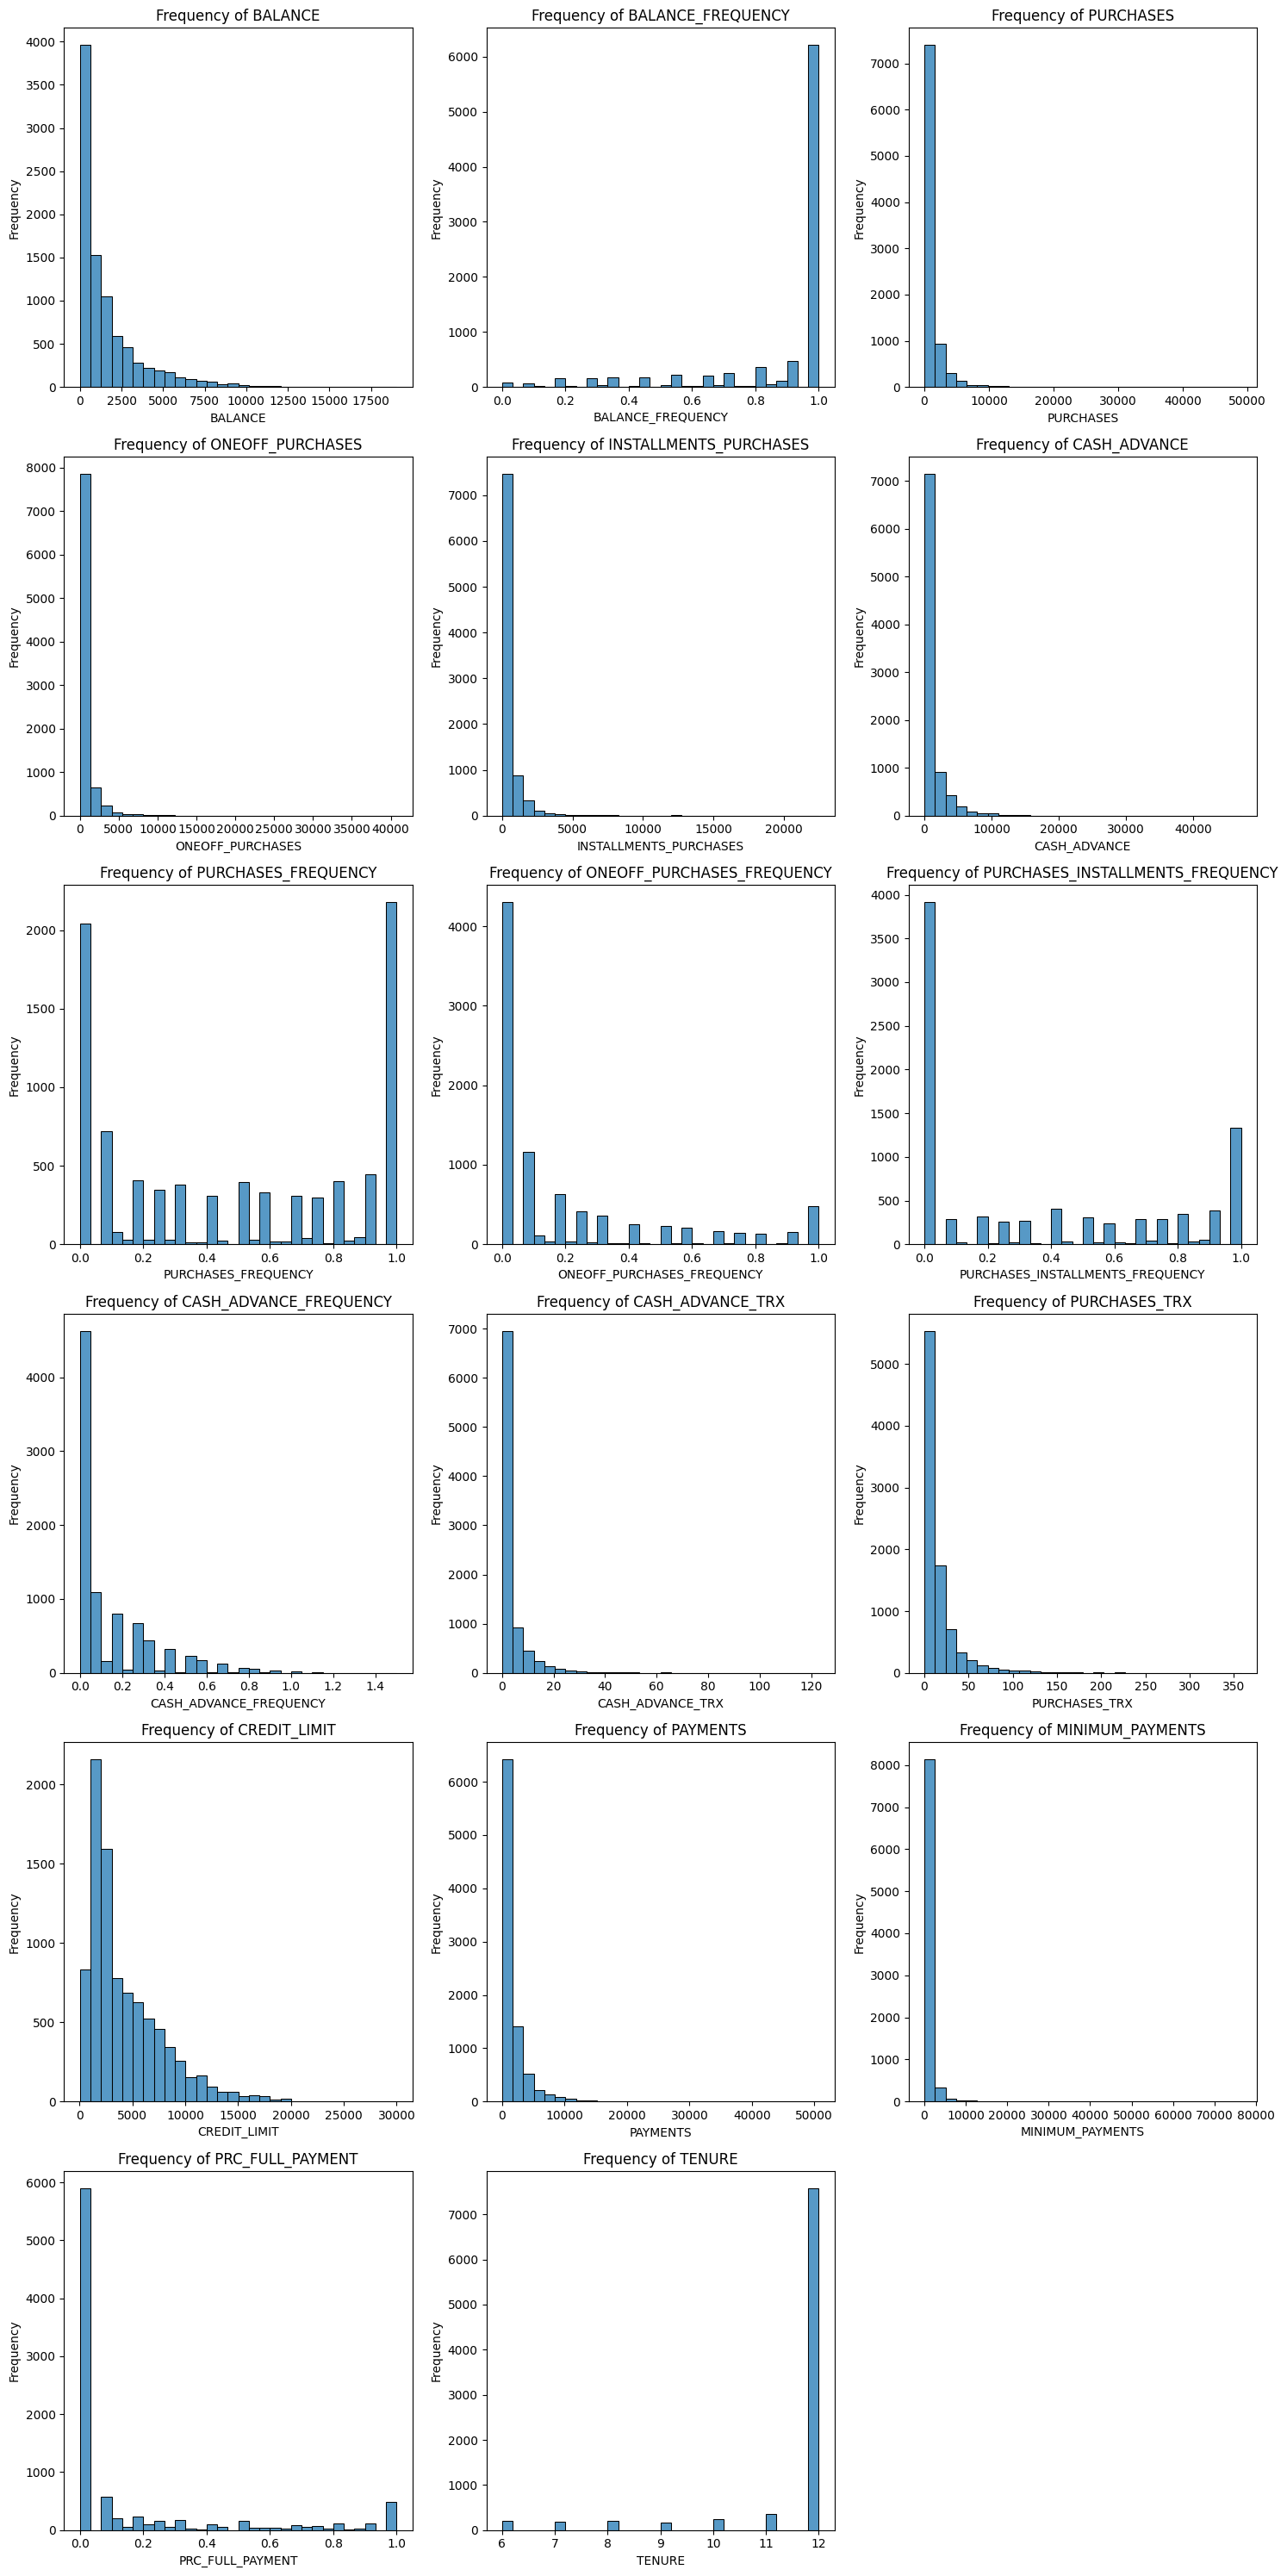

In [82]:
# Looking upon the distribution of various columns through Histograms

numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns

n_cols = 3
n_rows = len(numerical_columns) // n_cols + (len(numerical_columns) % n_cols > 0)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], kde=False, bins=30, ax=axes[i])  # kde=False for a pure histogram
    axes[i].set_title(f"Frequency of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [83]:
skewness = df.select_dtypes(include=['float64', 'int64']).skew()
print(skewness)

# [1] https://www.turing.com/kb/calculating-skewness-and-kurtosis-in-python

BALANCE                              2.393386
BALANCE_FREQUENCY                   -2.023266
PURCHASES                            8.144269
ONEOFF_PURCHASES                    10.045083
INSTALLMENTS_PURCHASES               7.299120
CASH_ADVANCE                         5.166609
PURCHASES_FREQUENCY                  0.060164
ONEOFF_PURCHASES_FREQUENCY           1.535613
PURCHASES_INSTALLMENTS_FREQUENCY     0.509201
CASH_ADVANCE_FREQUENCY               1.828686
CASH_ADVANCE_TRX                     5.721298
PURCHASES_TRX                        4.630655
CREDIT_LIMIT                         1.522464
PAYMENTS                             5.907620
MINIMUM_PAYMENTS                    13.622797
PRC_FULL_PAYMENT                     1.942820
TENURE                              -2.943017
dtype: float64


In [84]:
# Log Transormation - Heavily skewed data(long right tail)
# Power Transformation - Moderately Skewed data
# Expoential Transformation - Heavily kewed data(long left tail)

In [85]:
df['BALANCE'] = np.log1p(df['BALANCE'])
df['PURCHASES'] = np.log1p(df['PURCHASES'])
df['ONEOFF_PURCHASES'] = np.log1p(df['ONEOFF_PURCHASES'])
df['INSTALLMENTS_PURCHASES'] = np.log1p(df['INSTALLMENTS_PURCHASES'])
df['CASH_ADVANCE'] = np.log1p(df['CASH_ADVANCE'])
df['CASH_ADVANCE_TRX'] = np.log1p(df['CASH_ADVANCE_TRX'])
df['PURCHASES_TRX'] = np.log1p(df['PURCHASES_TRX'])
df['PAYMENTS'] = np.log1p(df['PAYMENTS'])
df['MINIMUM_PAYMENTS'] = np.log1p(df['MINIMUM_PAYMENTS'])
df['BALANCE_FREQUENCY'] = np.expm1(df['BALANCE_FREQUENCY'])
df['TENURE'] = np.expm1(df['TENURE'])




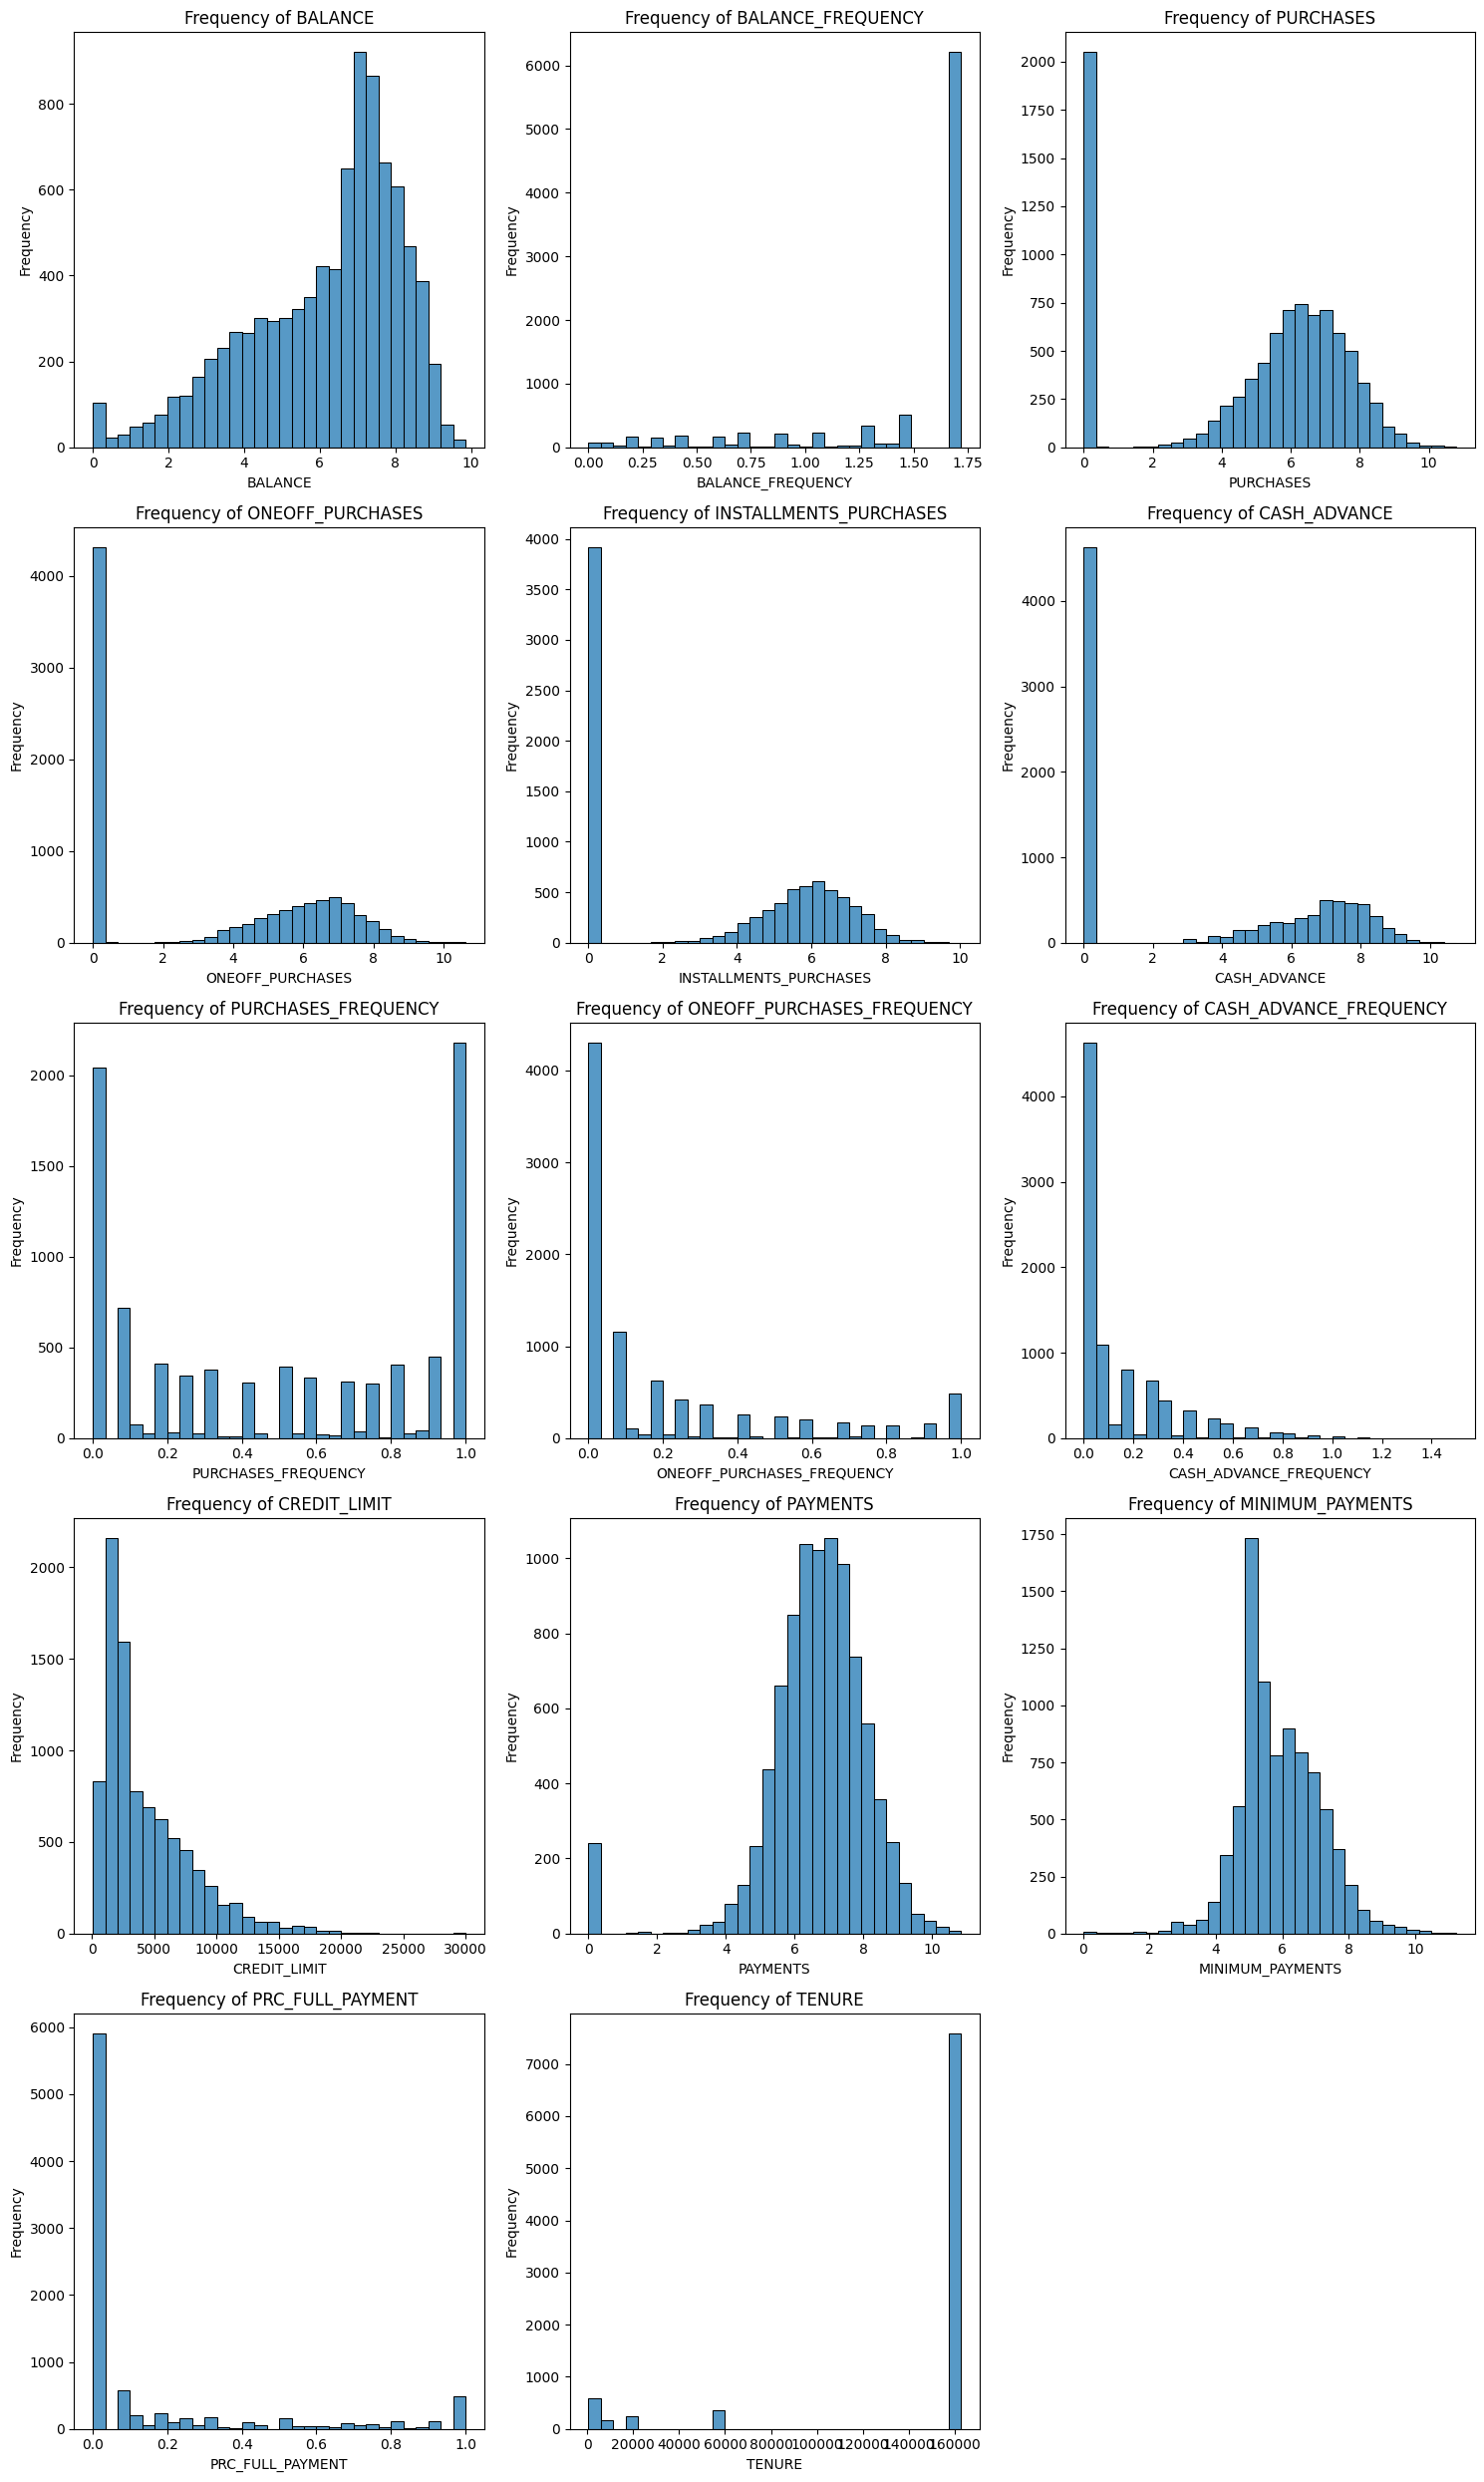

In [97]:
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns

n_cols = 3
n_rows = len(numerical_columns) // n_cols + (len(numerical_columns) % n_cols > 0)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], kde=False, bins=30, ax=axes[i])
    axes[i].set_title(f"Frequency of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# [2] https://chatgpt.com/share/674390ad-e7c8-8009-9816-b9667f2397dc

In [86]:
# Now after transformation, the skewness of different columns is fairly reduced

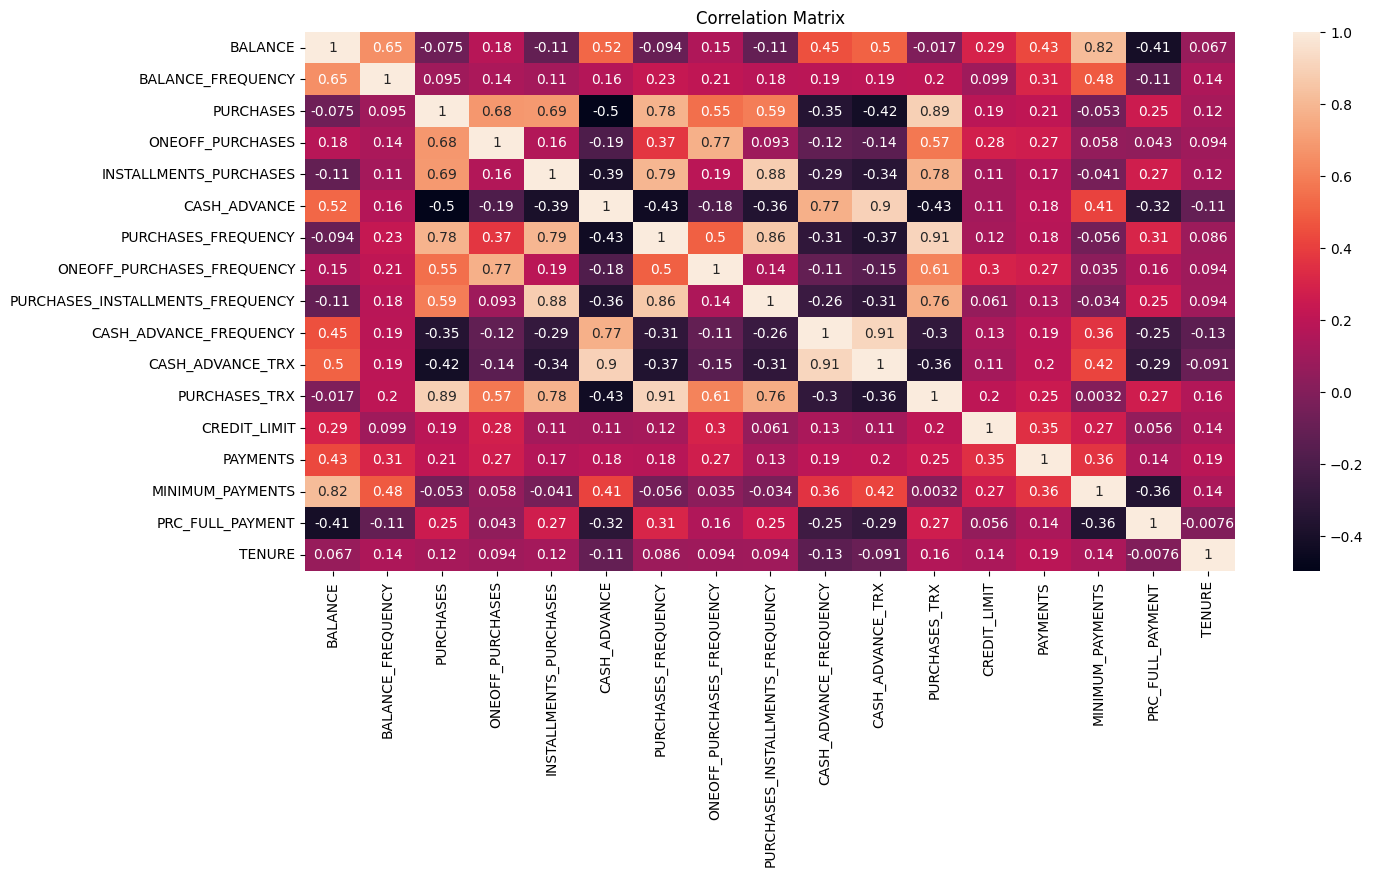

In [87]:
cor_mat = df.select_dtypes(include=[np.number]).corr()

fig = plt.figure(figsize=(15, 7))
sns.heatmap(cor_mat, annot=True)

plt.title("Correlation Matrix")
plt.show()

**Question 1b - Dropping highly correlated or inappropriate variables**

In [88]:
correlation_matrix = df.select_dtypes(include=['float64', 'int64']).corr()

threshold = 0.85

highly_correlated = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            highly_correlated.append(colname)

df = df.drop(columns=highly_correlated)

print(f"Dropped columns: {highly_correlated}")


Dropped columns: ['PURCHASES_INSTALLMENTS_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_TRX', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'PURCHASES_TRX']


**Question 2**

In [89]:
df1 = df.drop('CUST_ID', axis=1)
df1 = df1.dropna()

import altair as alt
from sklearn.cluster import KMeans

inertia = []
for n_clusters in range(2, 16):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(df1)
    inertia.append(kmeans.inertia_)

print('Inertia for each cluster:', inertia)

cluster_range = range(2, 16)
inertia_df = pd.DataFrame({'n_clusters': list(cluster_range), 'inertia': inertia})

chart = alt.Chart(inertia_df).mark_line(point=True).encode(
    x='n_clusters',
    y='inertia',
    tooltip=['n_clusters', 'inertia']
).properties(
    title='Inertia vs Number of Clusters'
)

chart

# [3] https://chatgpt.com/share/67439144-9660-8009-b892-15b1f2184b2a

Inertia for each cluster: [885463346027.5457, 181522348881.49377, 119510667726.15141, 52342184490.81763, 34788130789.707405, 29032345356.770706, 23528196176.02041, 20188467664.77939, 18355130452.73801, 16215069107.197311, 14794664990.507824, 11468416859.955633, 8408297479.565505, 7733580472.6430435]


alt.Chart(...)

In [90]:
# Optimum no. of clusters = 5

In [91]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(df1)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print(f"Number of clusters found by DBSCAN: {n_clusters}")

# [4] https://www.kdnuggets.com/2022/08/implementing-dbscan-python.html

Number of clusters found by DBSCAN: 35


In [92]:
from sklearn.metrics import silhouette_score

best_eps = None
best_min_samples = None
best_n_clusters = 0

for eps in np.arange(0.2, 2.0, 0.1):
    for min_samples in range(3, 10):
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(df1)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        if n_clusters == 5:
            best_eps = eps
            best_min_samples = min_samples
            best_n_clusters = n_clusters
            break

print(f"Best parameters: eps={best_eps}, min_samples={best_min_samples}, clusters={best_n_clusters}")


Best parameters: eps=None, min_samples=None, clusters=0


In [93]:
# We can't get the same number clusters from DB Scan as K-means

<ipython-input-94-cecee46307b1>:7: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c='blue', cmap='viridis')


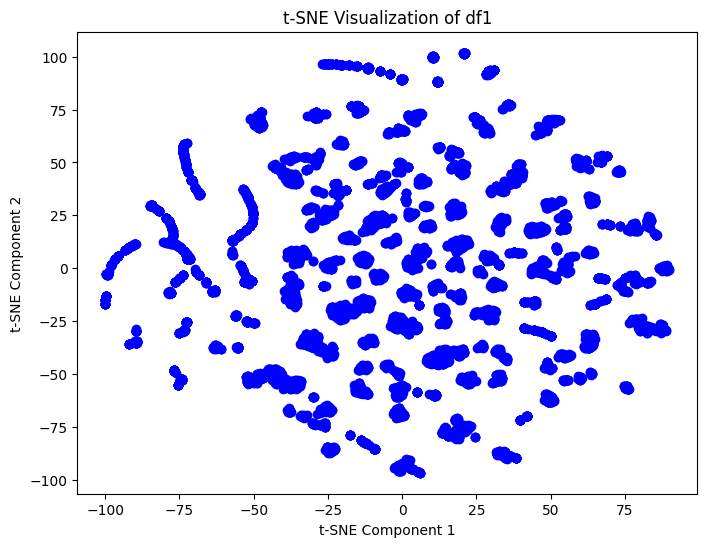

In [94]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(df1)

plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c='blue', cmap='viridis')
plt.title('t-SNE Visualization of df1')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()

#[5] https://builtin.com/data-science/tsne-python

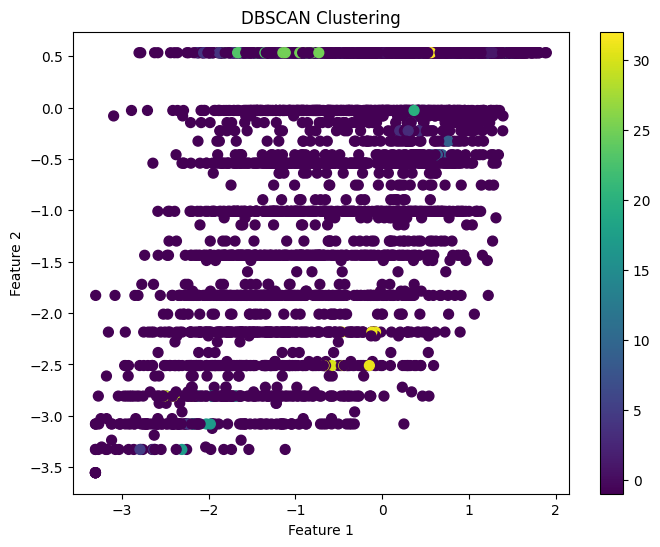

In [95]:
from sklearn.preprocessing import StandardScaler

X = df1.values

X_scaled = StandardScaler().fit_transform(X)
db = DBSCAN(eps=0.5, min_samples=5)
db_labels = db.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=db_labels, cmap='viridis', s=50)

plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.colorbar()
plt.show()


**Question 3**

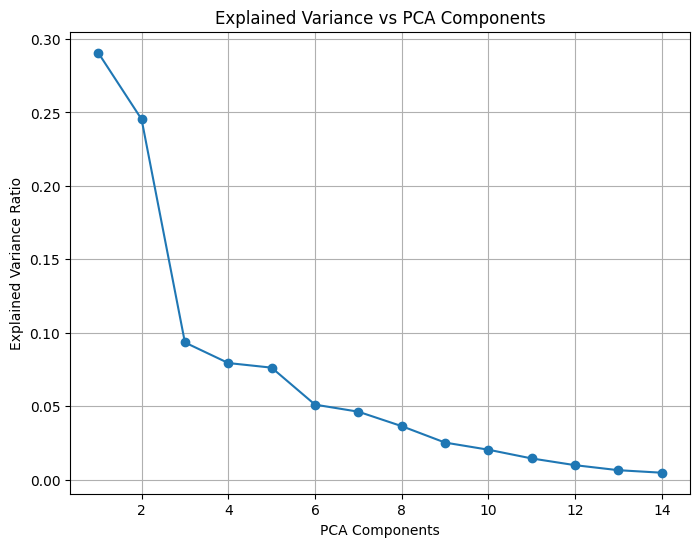

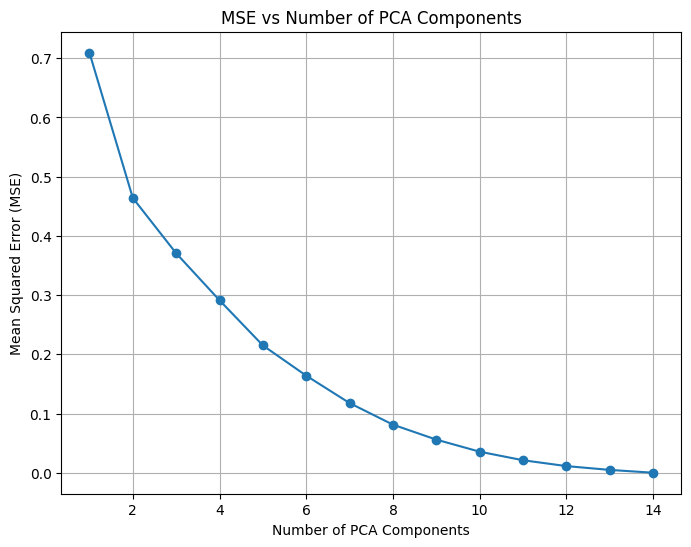

In [96]:
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

scaler = StandardScaler()
df1_normalized = scaler.fit_transform(df1)

pca = PCA()
pca.fit(df1_normalized)

explained_variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(8, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o')
plt.title("Explained Variance vs PCA Components")
plt.xlabel("PCA Components")
plt.ylabel("Explained Variance Ratio")
plt.grid(True)
plt.show()

mse_list = []

for k in range(1, len(df1.columns) + 1):
    pca = PCA(n_components=k)
    df1_reduced = pca.fit_transform(df1_normalized)

    df1_reconstructed = pca.inverse_transform(df1_reduced)

    mse = mean_squared_error(df1_normalized, df1_reconstructed)
    mse_list.append(mse)

plt.figure(figsize=(8, 6))
plt.plot(range(1, len(mse_list) + 1), mse_list, marker='o')
plt.title("MSE vs Number of PCA Components")
plt.xlabel("Number of PCA Components")
plt.ylabel("Mean Squared Error (MSE)")
plt.grid(True)
plt.show()

# [6] https://chatgpt.com/share/674391c6-cec0-8009-88e9-16abd66e07e9


**References Used**

[1] https://www.turing.com/kb/calculating-skewness-and-kurtosis-in-python
[2] https://chatgpt.com/share/674390ad-e7c8-8009-9816-b9667f2397dc
[3] https://chatgpt.com/share/67439144-9660-8009-b892-15b1f2184b2a
[4] https://www.kdnuggets.com/2022/08/implementing-dbscan-python.html
[5] https://builtin.com/data-science/tsne-python
[6] https://chatgpt.com/share/674391c6-cec0-8009-88e9-16abd66e07e9